# Dimensionality Reduction - Data Science Portfolio - Mai Bui

**Dataset:** Wine Quality (red wine)

**Target variable:** Predicting wine quality rating

**Features:** 11 physicochemical measurements (e.g. acidity, sugar, chlorides, sulfur dioxide, density, pH, sulphates, alcohol)

**Techniques applied:** PCA, Logistic Regression, KNN, t-SNE


Dimensionality reduction reduces the number of features while retaining as much predictive power as possible. This is helpful when features are highly correlated and for lowering computational complexity.

For demonstration, I chose the Wine Quality dataset, which contains 1,143 red wine samples with 11 continuous chemical measurements and a quality rating. Many of these chemical properties are correlated, which makes the dataset a good candidate for PCA. PCA can compress the data into fewer dimensions without losing much predictive signal, making downstream modelling faster and reducing the risk of overfitting. It also makes it possible to visualise in 2D a dataset that would otherwise be impossible to plot directly.

In this notebook I will:
- Apply PCA to the wine data and choose the number of components from the explained variance
- Compare the performance of Logistic Regression and KNN on the original 11 features against the PCA-reduced features
- Interpret the PCA dimensions and visualise the data with PCA and t-SNE


The dataset is a plain CSV file, so it can be loaded directly with pandas. It has no missing values. The Id and quality columns are excluded from the feature set, and the 11 features are standardised with StandardScaler before PCA, since PCA is sensitive to feature scale. The quality classes are imbalanced, so I report both accuracy and balanced accuracy. The focus is on how much performance is retained after reduction rather than on maximising absolute accuracy.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.discriminant_analysis import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.manifold import TSNE


In [2]:
df = pd.read_csv("datasets/dimensionality_dataset.csv")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,2
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,3
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595


The dataset used in this analysis is the Wine Quality dataset, which contains 11 physicochemical measurements for red wine samples, along with a quality rating. With 11 continuous features, the dataset is a good candidate for dimensionality reduction as many of these chemical properties are likely correlated. PCA can identify the directions of maximum variance and compress the data into fewer dimensions without losing much predictive signal, making downstream modelling faster and reducing the risk of overfitting. It also enables 2D visualisation of a dataset that would otherwise be impossible to plot directly.

In [3]:
print('\nMissing values:', df.isnull().sum().sum())


Missing values: 0


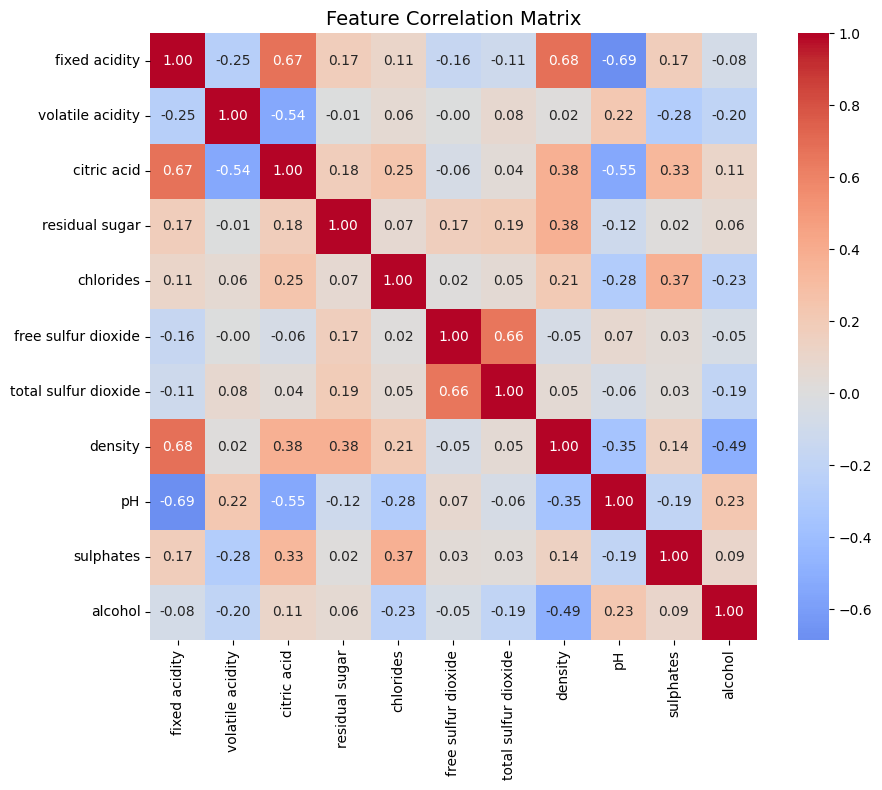

In [4]:
feature_cols = [c for c in df.columns if c not in ['quality', 'Id']]

fig, ax = plt.subplots(figsize=(10, 8))
corr_matrix = df[feature_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=ax)
ax.set_title('Feature Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.show()

Several features show strong correlations which means that the 11 features may contain redundant information that PCA can compress.

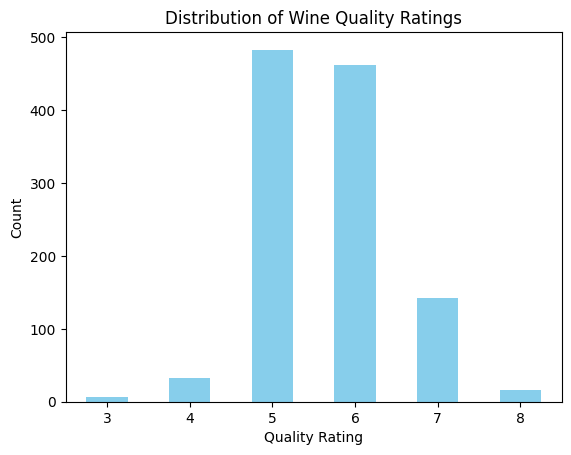

In [5]:
df['quality'].value_counts().sort_index().plot(kind='bar', color='skyblue')
plt.title('Distribution of Wine Quality Ratings')
plt.xlabel('Quality Rating')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

There is a class imbalance that will impact (balanced) accuracy. However, as we are more interested in how much accuracy retention after applying dimensionality reduction, we will leave the data be.

# Preprocessing

In [6]:
X = df[feature_cols].values
y = df['quality'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

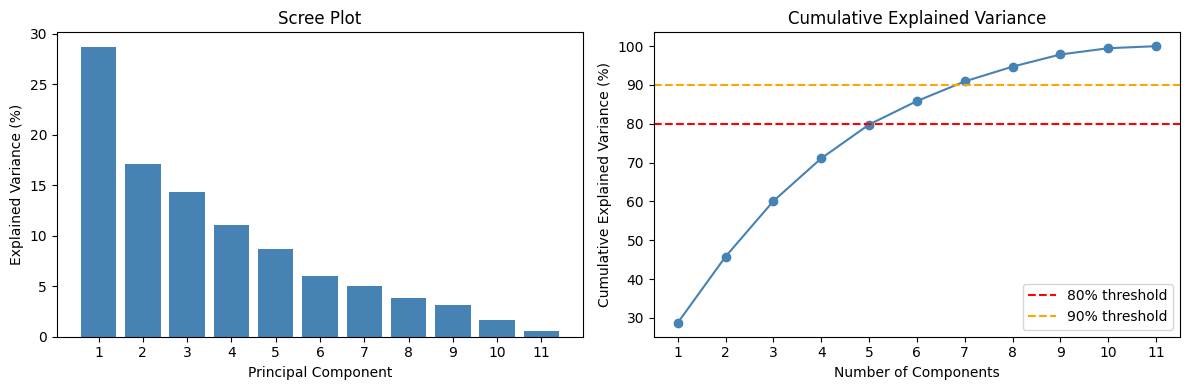

PC1: 28.7% variance | Cumulative: 28.7%
PC2: 17.1% variance | Cumulative: 45.8%
PC3: 14.3% variance | Cumulative: 60.1%
PC4: 11.0% variance | Cumulative: 71.1%
PC5: 8.7% variance | Cumulative: 79.8%
PC6: 6.0% variance | Cumulative: 85.8%
PC7: 5.1% variance | Cumulative: 90.9%
PC8: 3.8% variance | Cumulative: 94.7%
PC9: 3.1% variance | Cumulative: 97.9%
PC10: 1.6% variance | Cumulative: 99.5%
PC11: 0.5% variance | Cumulative: 100.0%


In [7]:
# Fit PCA on all components first to inspect explained variance
pca_full = PCA(random_state=42)

pca_full.fit(X_scaled)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Scree plot
axes[0].bar(range(1, len(explained_var) + 1), explained_var * 100, color='steelblue')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot')
axes[0].set_xticks(range(1, len(explained_var) + 1))

# Cumulative explained variance
axes[1].plot(range(1, len(cumulative_var) + 1), cumulative_var * 100,
             marker='o', color='steelblue')
axes[1].axhline(y=80, color='red', linestyle='--', label='80% threshold')
axes[1].axhline(y=90, color='orange', linestyle='--', label='90% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xticks(range(1, len(cumulative_var) + 1))
axes[1].legend()

plt.tight_layout()
plt.show()

for i, (ev, cum) in enumerate(zip(explained_var, cumulative_var), 1):
    print(f"PC{i}: {ev*100:.1f}% variance | Cumulative: {cum*100:.1f}%")

In [ ]:
N_COMPONENTS = 6   # captures ~86% of variance for this dataset

pca = PCA(n_components=N_COMPONENTS, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Reduced shape: {X_pca.shape}")
print(f"Total variance retained with {N_COMPONENTS} components: "
      f"{pca.explained_variance_ratio_.sum()*100:.1f}%")

Reduced shape: (1143, 6)
Total variance retained with 6 components: 85.8%


# Comparision

To  evaluate how well the PCA embedding preserves the information in the original data, I will train 2 models: 1 with the original 11 features as our base model, and 1 with the PCA-reduced features.

We also report a Logistic Regression (which assumes linear separability) and a KNN classifier (which is non-linear), to see whether the structure preserved by PCA is linear or non-linear in nature.

In [9]:
def evaluate_classifier(clf, X_train, y_train, label):
    """Run 5-fold cross-validation and print mean accuracy + balanced accuracy."""
    acc_scores  = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
    bal_scores  = cross_val_score(clf, X_train, y_train, cv=5, scoring='balanced_accuracy')
    print(f"{label}  Accuracy: {acc_scores.mean():.3f} ± {acc_scores.std():.3f} | "
          f"Balanced Accuracy: {bal_scores.mean():.3f} ± {bal_scores.std():.3f}")
    return acc_scores.mean(), bal_scores.mean()

lr  = LogisticRegression(max_iter=1000, random_state=42)
knn = KNeighborsClassifier(n_neighbors=7)

In [10]:
acc_lr_orig,  bal_lr_orig  = evaluate_classifier(lr,  X_scaled, y, "Logistic Regression: Original (11 features) |")
acc_lr_pca,   bal_lr_pca   = evaluate_classifier(lr,  X_pca,    y, f"Logistic Regression: PCA ({N_COMPONENTS} components) |")

acc_knn_orig, bal_knn_orig = evaluate_classifier(knn, X_scaled, y, "KNN (k=7): Original (11 features) |")
acc_knn_pca,  bal_knn_pca  = evaluate_classifier(knn, X_pca,    y, f"KNN (k=7): PCA ({N_COMPONENTS} components) |")

Logistic Regression: Original (11 features) |  Accuracy: 0.592 ± 0.030 | Balanced Accuracy: 0.277 ± 0.025
Logistic Regression: PCA (6 components) |  Accuracy: 0.578 ± 0.034 | Balanced Accuracy: 0.268 ± 0.028
KNN (k=7): Original (11 features) |  Accuracy: 0.551 ± 0.039 | Balanced Accuracy: 0.264 ± 0.036
KNN (k=7): PCA (6 components) |  Accuracy: 0.512 ± 0.030 | Balanced Accuracy: 0.243 ± 0.029


In [11]:
print(f"Retention (LR):  Accuracy {acc_lr_pca/acc_lr_orig*100:.1f}% | Balanced Accuracy {bal_lr_pca/bal_lr_orig*100:.1f}%")
print(f"Retention (KNN): Accuracy {acc_knn_pca/acc_knn_orig*100:.1f}% | Balanced Accuracy {bal_knn_pca/bal_knn_orig*100:.1f}%")

Retention (LR):  Accuracy 97.6% | Balanced Accuracy 96.8%
Retention (KNN): Accuracy 92.9% | Balanced Accuracy 91.9%


Logistic Regression drops from 59.2% to 57.8% accuracy when switching from 11 features to just 6 PCA components. We only loss 1.4 percent points even when we discard 5 dimensions, which means that the dropped components contained mostly noise, not signal. Similar logic can be applied to KNN as the accuracy drops from 55.1% → 51.2%.


LR retains 97.6%, which is lmost no loss. This suggests the quality-related structure in the data is largely linear, and PCA (which is itself a linear method) captures it well. KNN drops more (92.9%) because it relies on exact distances between points. Compressing to 6 dimensions slightly distorts local neighbourhoods, which KNN is sensitive to.

# Visualisation & Interpretation

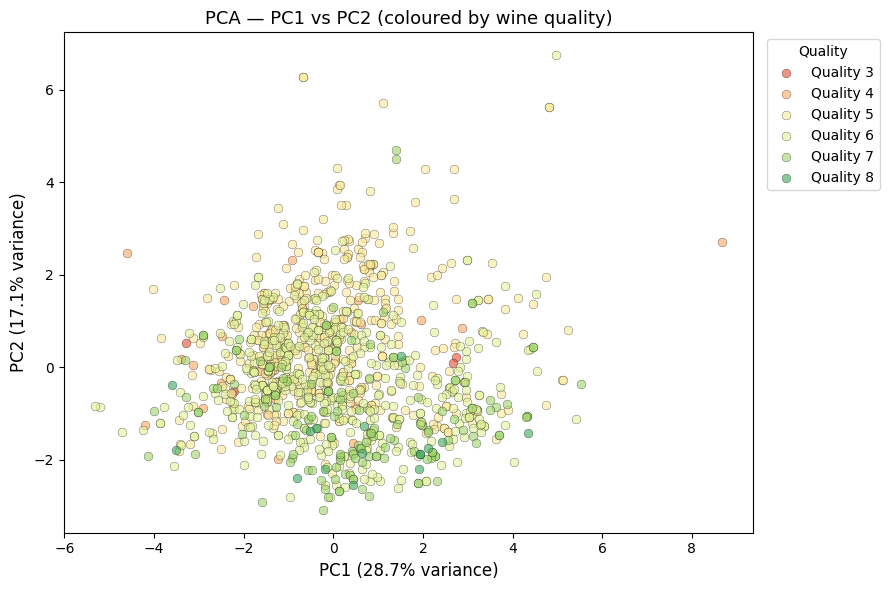

Variance captured by 2D PCA: 45.8%


In [12]:

# Use 2D PCA for visualisation (separate from the N_COMPONENTS used for modelling)
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

quality_values = sorted(df['quality'].unique())
palette = sns.color_palette("RdYlGn", len(quality_values))
color_map = dict(zip(quality_values, palette))

fig, ax = plt.subplots(figsize=(9, 6))

for q in quality_values:
    mask = y == q
    ax.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
               label=f'Quality {q}', color=color_map[q],
               alpha=0.6, edgecolors='k', linewidths=0.3, s=40)

ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
ax.set_title('PCA — PC1 vs PC2 (coloured by wine quality)', fontsize=13)
ax.legend(title='Quality', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

print(f"Variance captured by 2D PCA: "
      f"{pca_2d.explained_variance_ratio_.sum()*100:.1f}%")

The data does not form cleanly separated clusters by quality in the first two principal components. This is expected, since only ~45.8% of variance is captured in 2D.

PC1 appears to encode an overall chemical strength axis (likely driven by alcohol and acidity loadings) where a weak quality gradient is visible as lower-quality wines cluster to the left and higher-quality wines to the right. 

The  overlap between classes is expected given that quality is a subjective, continuous label and only ~46% of variance is captured in this projection. The lack of sharp boundaries motivates the use of all 5 PCA components for downstream classification rather than this 2D reduction alone.

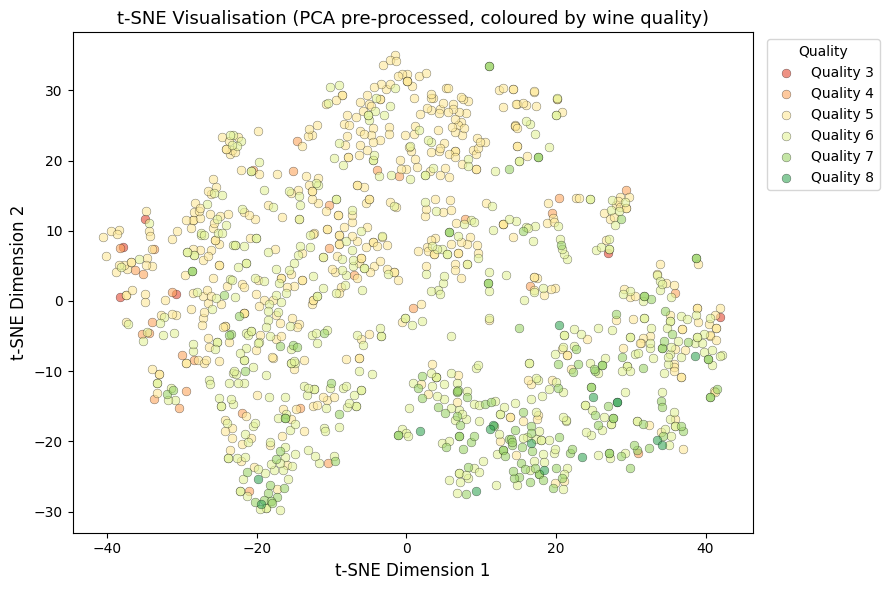

In [13]:
# t-SNE visualisation (applied to PCA-reduced data)
# We run t-SNE on X_pca (the 6-component embedding) rather than raw X_scaled to reduce noise and computation time
tsne = TSNE(n_components=2, perplexity=40, max_iter=1000, random_state=42)
X_tsne = tsne.fit_transform(X_pca)   # input is already PCA-reduced

fig, ax = plt.subplots(figsize=(9, 6))

for q in quality_values:
    mask = y == q
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1],
               label=f'Quality {q}', color=color_map[q],
               alpha=0.6, edgecolors='k', linewidths=0.3, s=40)

ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
ax.set_title('t-SNE Visualisation (PCA pre-processed, coloured by wine quality)', fontsize=13)
ax.legend(title='Quality', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

t-SNE reveals more local structure than PCA. We can observe loose groupings of wines, but quality grades are still substantially overlapping, confirming that wine quality is a continuous, noisy label, so it is not cleanly separable by physicochemical features alone.

PCA proved to be an appropriate and effective dimensionality reduction technique for this dataset, compressing 11 correlated features into a compact embedding that preserves both statistical variance and predictive power.